# Одно смешивание вероятностей: 50% AGMFA + 50% старого ансамбля
Никакого нового обучения, inference, ранжировщика, подбора весов или температуры.
Старый ансамбль = 50% ResNet101(original) + 50% ResNet50(D4);
итоговые доли = 0.5 AGMFA + 0.25 ResNet101 + 0.25 ResNet50 D4.

Val использует **только train-only** модели. Здесь AGMFA — сохранённый B
best_loss эпохи22, cosine T_max24; val probabilities отдельного fresh final_train
с cosine22 в проекте отсутствуют. Это явно обозначенный proxy train-only recipe,
а не оценка train+val модели на её собственных обучающих объектах.
Train+val решения используются только в необязательном test export.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.probability_fusion import analyze_fusion,save_validation_report,case_gallery,export_test_fusion

RUN_ID='probability_fusion_001'
RAW_DIR=ROOT/'data/raw'
AGMFA_VAL=ROOT/'artifacts/predictions/resnet50_agmfa_hard_target_shift_001/val_best_loss_probabilities.npz'
OLD_VAL=ROOT/'artifacts/predictions/quality_resnet101_saved_001/selected_probabilities.npz'
SHOW_GALLERIES=True
CASE_LIMIT=12
SMALL_OBJECT_IDS=[]  # val IDs из ручного анализа, если нужно
RUN_TEST_FUSION=False  # Только export сохранённых train+val probabilities, без сети/GPU


In [2]:
agmfa_summary=json.loads((ROOT/'artifacts/logs/resnet50_agmfa_hard_target_shift_001/summary.json').read_text())
assert agmfa_summary['best_loss_epoch']==22
old_manifest=json.loads((ROOT/'artifacts/logs/quality_resnet101_saved_001/selection.json').read_text())
assert [(m['name'],m['tta'],m['weight']) for m in old_manifest['members']]==[('resnet101','none',.5),('stronger','d4',.5)]
assert all('final_train_val' not in m['checkpoint'] for m in old_manifest['members'])

result=analyze_fusion(AGMFA_VAL,OLD_VAL,RAW_DIR/'classes.csv',val_dir=RAW_DIR/'val')
context={'agmfa':'train-only B, best_loss epoch22, cosine T_max24; final_train cosine22 cache absent',
         'old_ensemble':old_manifest['recipe'],'selection':'weights fixed50/50; no search',
         'confidence_thresholds':[.9,.95]}
paths=save_validation_report(result,ROOT,RUN_ID,AGMFA_VAL,OLD_VAL,context)
display(result['metrics'])
display(result['complementarity'])
display(result['groups'])
display(result['per_class'].sort_values('old_ensemble_errors',ascending=False))


,model,correct,errors,accuracy,nll,brier,mean_wrong_confidence,confident_errors_90,confident_errors_95
0,agmfa,674,25,0.964235,0.109995,0.058696,0.732577,4,3
1,old_ensemble,679,20,0.971388,0.132275,0.052133,0.806797,9,9
2,blend_50_50,678,21,0.969957,0.097829,0.050104,0.728942,4,4


,category,count
0,both_correct,669
1,both_wrong,15
2,only_agmfa_correct,5
3,only_old_correct,10
4,blend_fixed_old,3
5,blend_broke_old,4
6,blend_fixed_agmfa,6
7,blend_broke_agmfa,2


,group,support,agmfa_errors,old_ensemble_errors,blend_50_50_errors,fixed_old,broke_old
0,church/palace,70,10,8,9,1,2
1,railway/station,70,4,1,2,0,1
2,lake/wetland,70,4,4,4,0,0
3,courts,70,3,4,3,1,0


,label,class_name,support,agmfa_errors,old_ensemble_errors,blend_50_50_errors,fixed_old,broke_old
3,3,church,35,9,6,8,0,2
1,1,basketball_court,35,3,3,3,0,0
6,6,lake,35,3,3,3,0,0
9,9,palace,35,1,2,1,1,0
18,18,terrace,35,1,2,1,1,0
0,0,baseball_diamond,35,1,1,1,0,0
17,17,tennis_court,35,0,1,0,1,0
11,11,railway_station,35,2,1,2,0,1
19,19,wetland,35,1,1,1,0,0
2,2,bridge,34,0,0,0,0,0


## Исправления и регрессии: отдельные объекты
NLL/Brier отражают качество вероятностей, Accuracy — argmax ответы.
Уверенная ошибка: максимум вероятностей >=90%/95% (пороги фиксированы заранее).
Улучшение NLL при потере одного верного ответа не доказывает улучшение test Accuracy.
Все изменения показаны открыто; 50/50 не подгоняется под эти таблицы.


,id,true_label,agmfa_label,old_ensemble_label,blend_50_50_label,agmfa_confidence,old_ensemble_confidence,blend_50_50_confidence,brightness,contrast,detail
1,32.jpg,palace,palace,commercial_area,palace,0.832582,0.620523,0.605693,0.331167,0.148255,0.025844
236,4761.jpg,tennis_court,tennis_court,church,tennis_court,0.576834,0.413380,0.396501,0.284694,0.144444,0.022185
292,5900.jpg,railway_station,railway,railway_station,railway,0.846198,0.557518,0.642774,0.315910,0.122411,0.022242
372,7548.jpg,church,commercial_area,church,commercial_area,0.783733,0.498364,0.640655,0.424280,0.182795,0.014208
451,9099.jpg,commercial_area,church,commercial_area,palace,0.519152,0.485147,0.376119,0.348909,0.202182,0.040392
506,10144.jpg,church,palace,church,palace,0.737453,0.513072,0.612177,0.256988,0.166952,0.023055
519,10371.jpg,terrace,terrace,rectangular_farmland,terrace,0.599395,0.542563,0.528398,0.293308,0.078798,0.007506


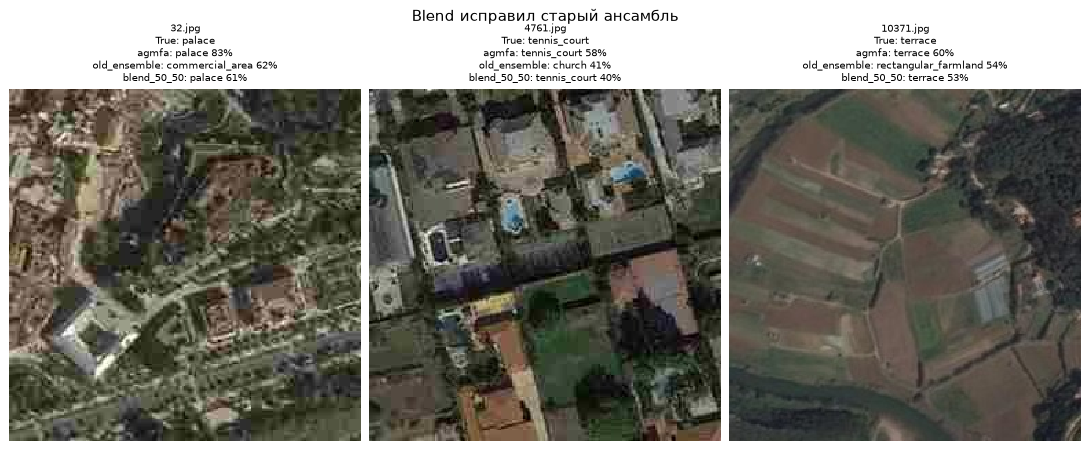

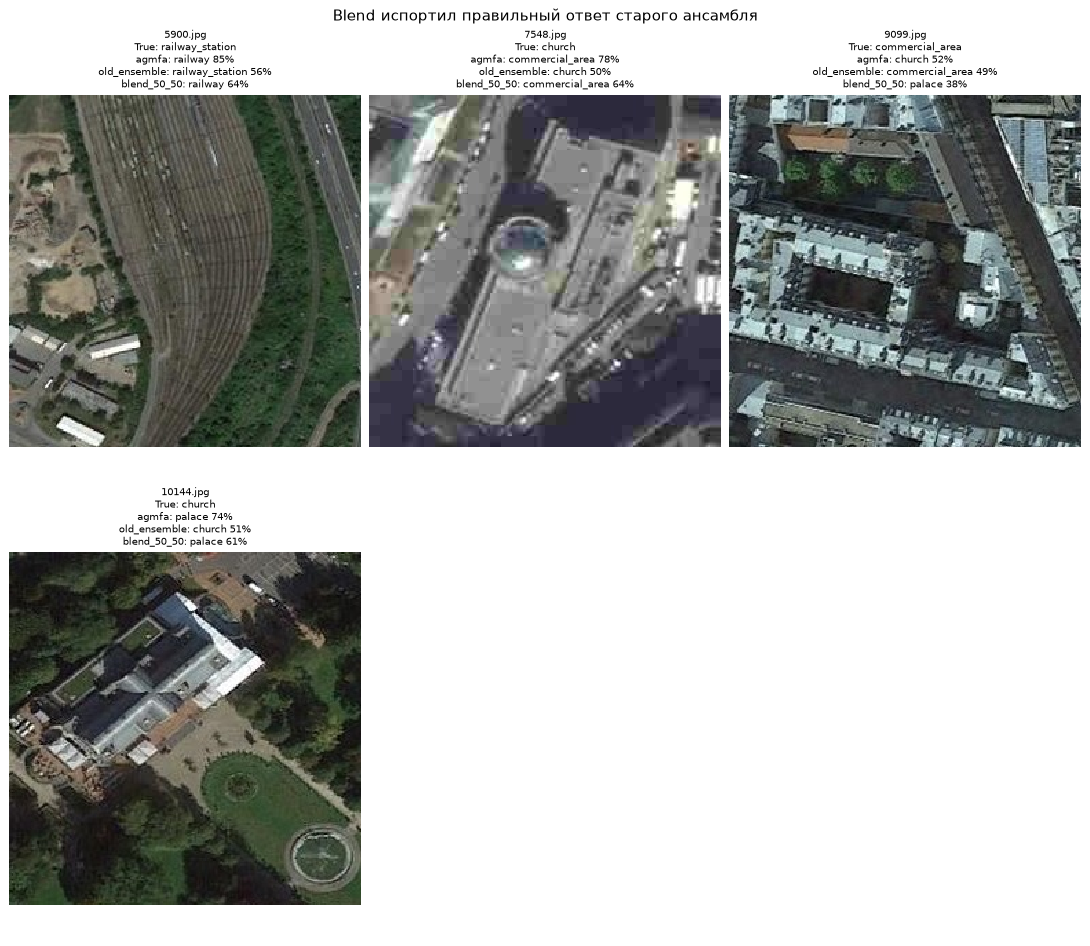

In [3]:
frame=result['frame']
changed=frame[frame.old_ensemble_correct != frame.blend_50_50_correct].copy()
columns=['id','true_label','agmfa_label','old_ensemble_label','blend_50_50_label',
         'agmfa_confidence','old_ensemble_confidence','blend_50_50_confidence',
         'brightness','contrast','detail']
class_names=result['classes'].set_index('label').class_name.to_dict()
view=changed[columns].copy()
for name in ['true_label','agmfa_label','old_ensemble_label','blend_50_50_label']:
    view[name]=view[name].map(class_names)
display(view)
if SHOW_GALLERIES:
    case_gallery(result,frame[~frame.old_ensemble_correct & frame.blend_50_50_correct],
                 'Blend исправил старый ансамбль',RAW_DIR/'val',CASE_LIMIT)
    case_gallery(result,frame[frame.old_ensemble_correct & ~frame.blend_50_50_correct],
                 'Blend испортил правильный ответ старого ансамбля',RAW_DIR/'val',CASE_LIMIT)


Detail/brightness — диагностические proxies, не разметка деградаций или размера объекта.


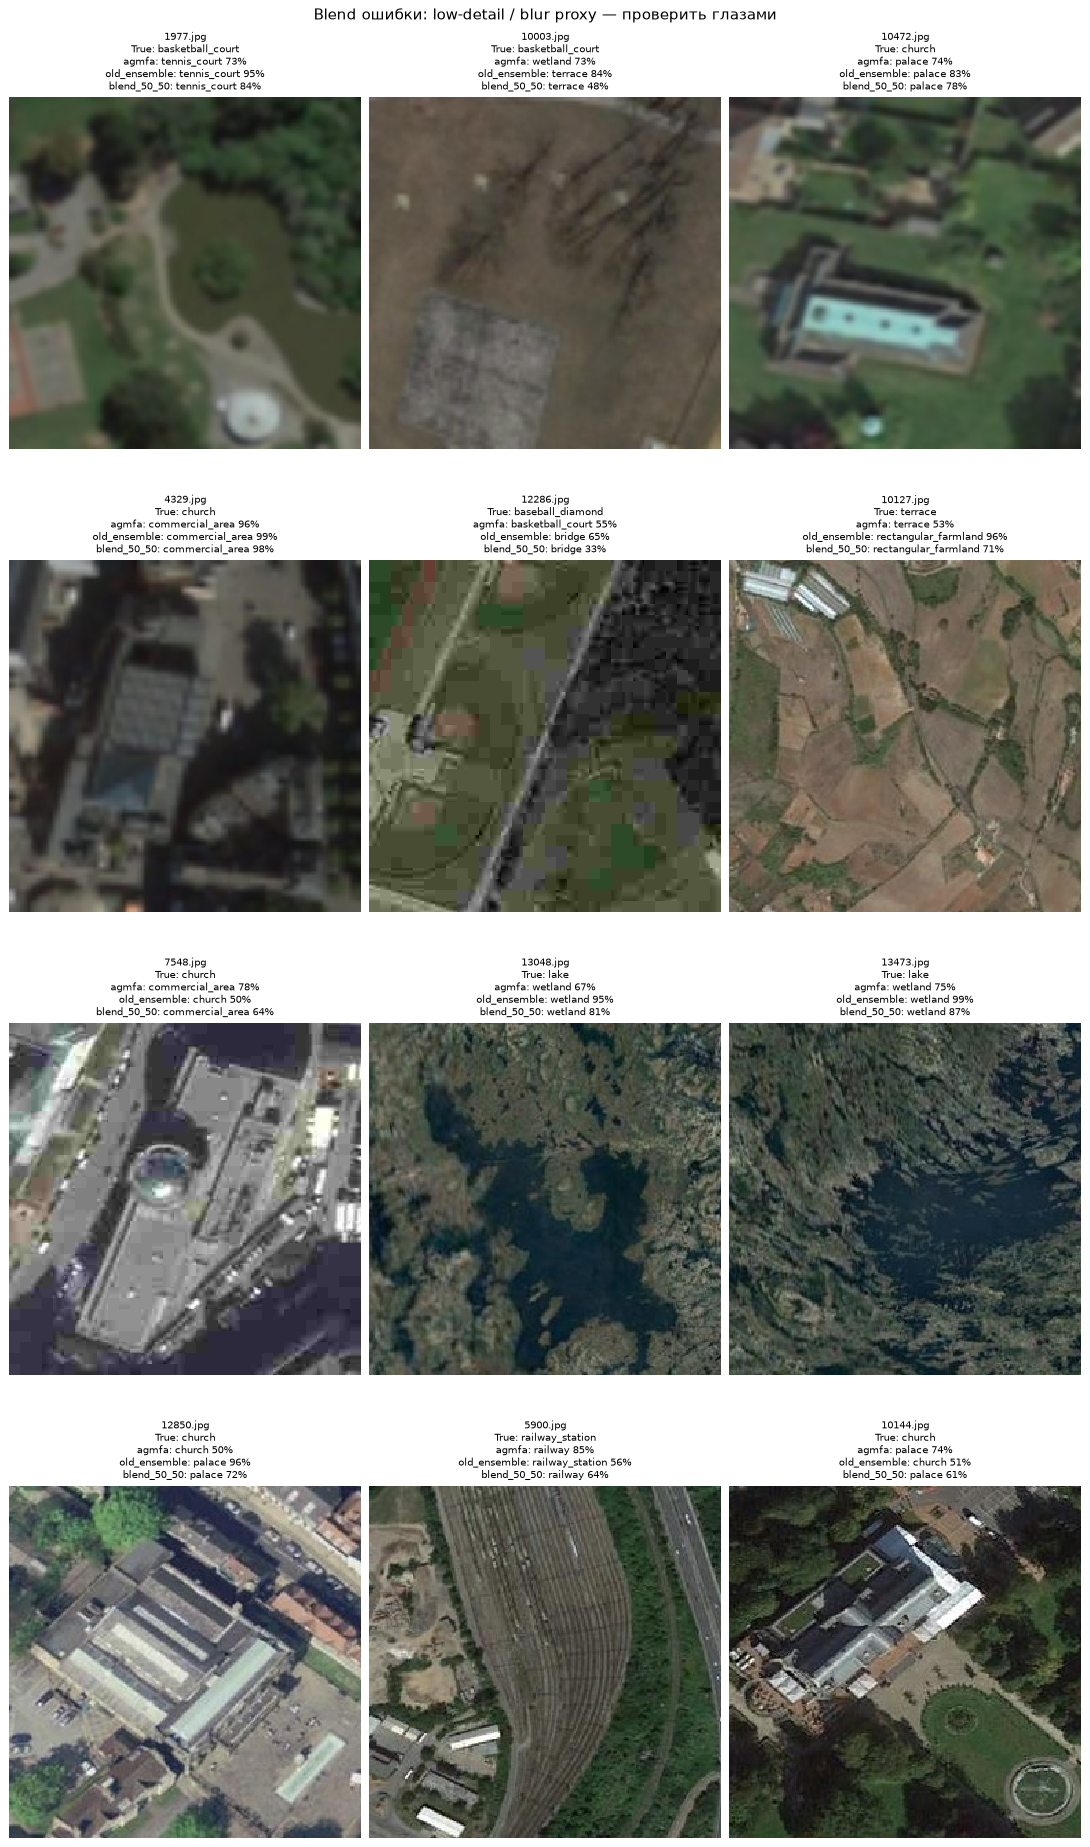

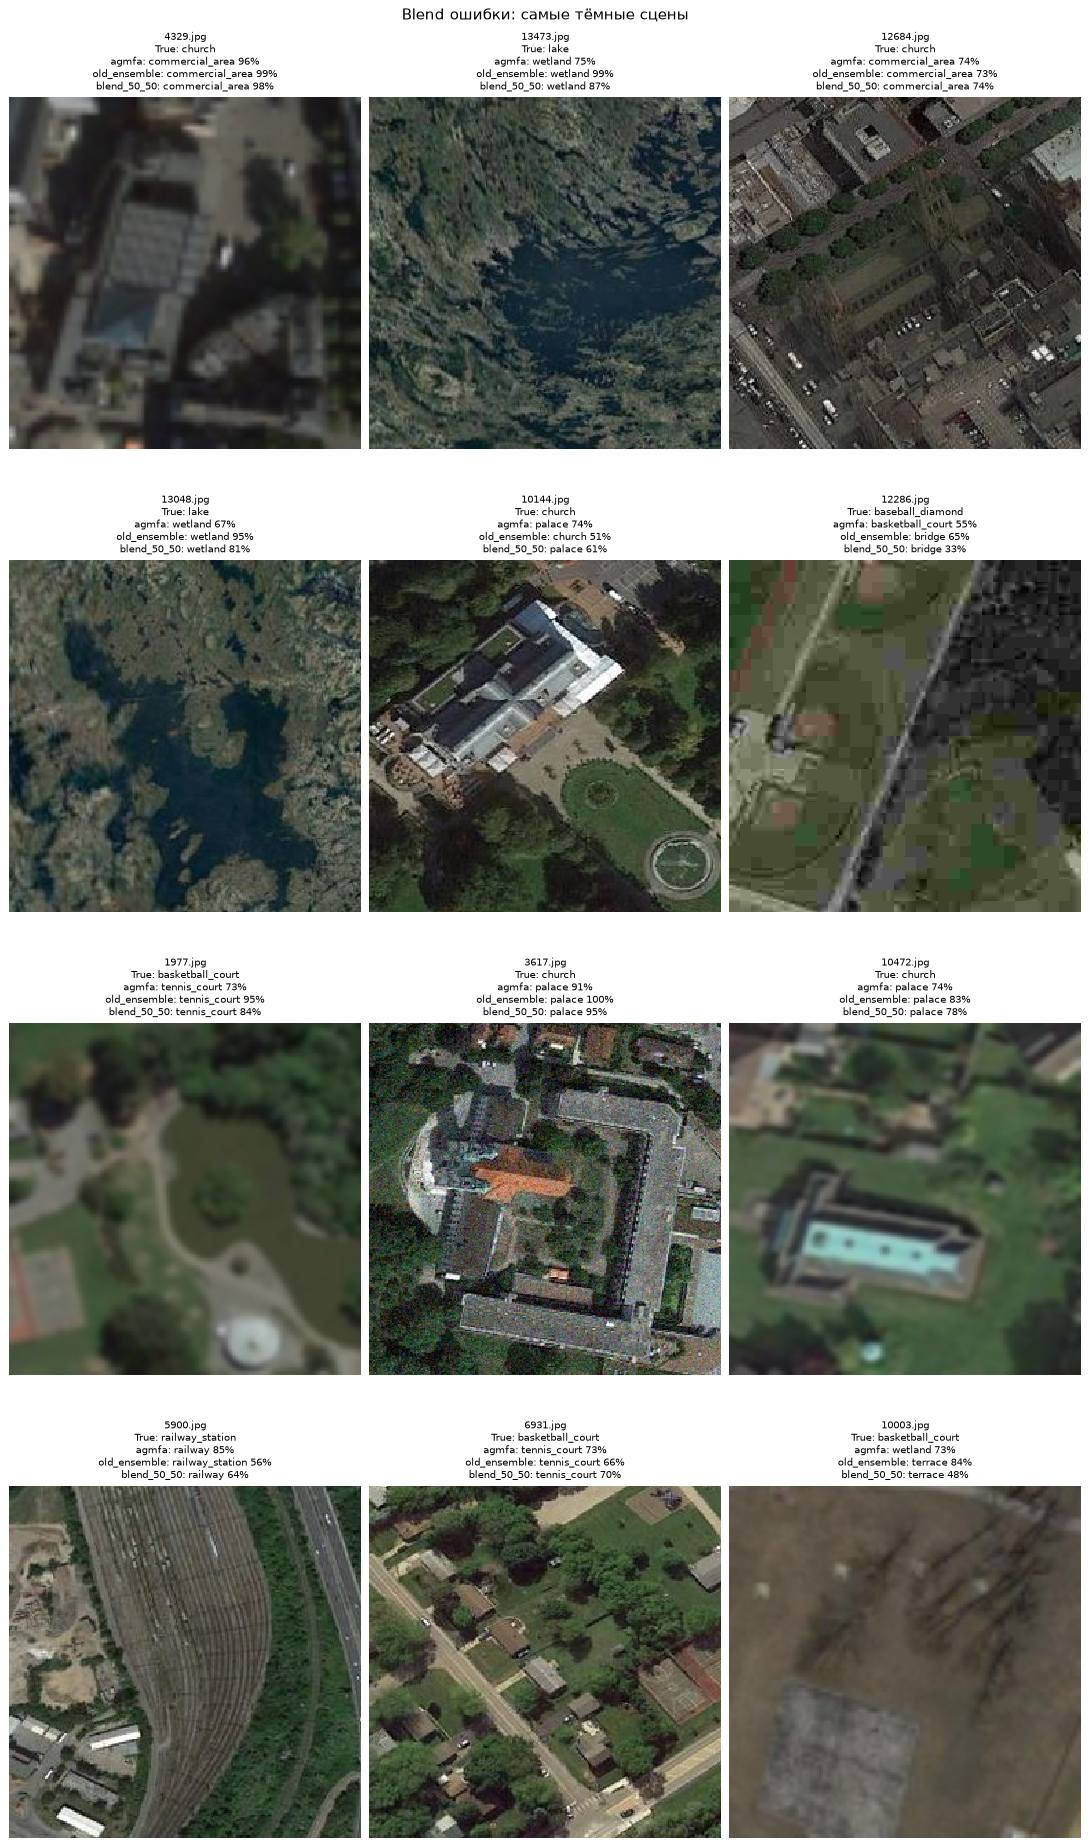

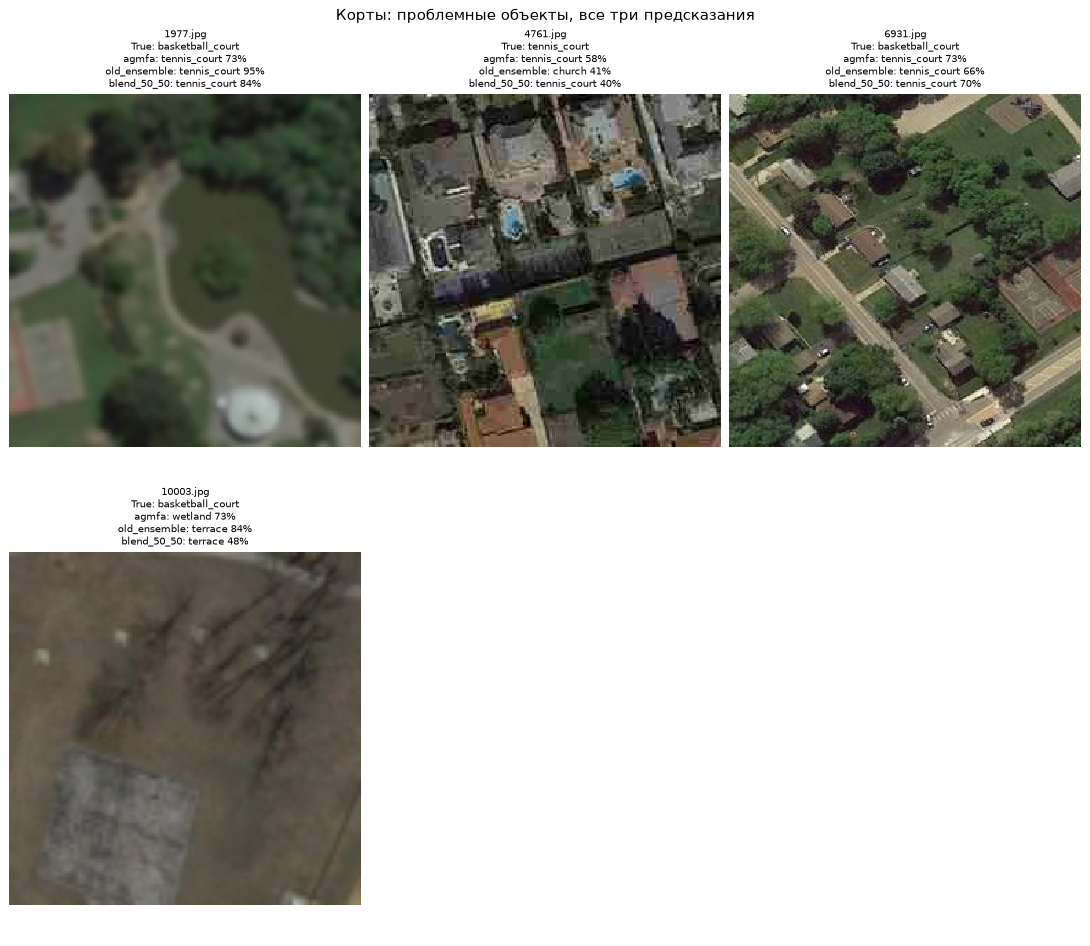

In [4]:
if SHOW_GALLERIES:
    wrong=frame[~frame.blend_50_50_correct]
    case_gallery(result,wrong.nsmallest(CASE_LIMIT,'detail'),
                 'Blend ошибки: low-detail / blur proxy — проверить глазами',RAW_DIR/'val',CASE_LIMIT)
    case_gallery(result,wrong.nsmallest(CASE_LIMIT,'brightness'),
                 'Blend ошибки: самые тёмные сцены',RAW_DIR/'val',CASE_LIMIT)
    court_labels=result['classes'].loc[result['classes'].class_name.isin(['tennis_court','basketball_court']),'label']
    case_gallery(result,frame[frame.true_label.isin(court_labels) & (~frame.agmfa_correct | ~frame.old_ensemble_correct | ~frame.blend_50_50_correct)],
                 'Корты: проблемные объекты, все три предсказания',RAW_DIR/'val',CASE_LIMIT)
    if SMALL_OBJECT_IDS:
        case_gallery(result,frame[frame.id.isin(SMALL_OBJECT_IDS)],'Ручные small-object случаи',RAW_DIR/'val',CASE_LIMIT)
print('Detail/brightness — диагностические proxies, не разметка деградаций или размера объекта.')


## Вывод выполненной проверки
Старый ансамбль: **679/699**, смесь: **678/699**. Исправлено 3, испорчено 4.
NLL: **0.1323 → 0.0978**; ошибок с confidence ≥90%: **9 → 4**.
Один фиксированный test-кандидат сохранён благодаря улучшению вероятностей
и дополнению моделей; это **не доказанный выигрыш Accuracy**.
Подробный разбор: `../docs/probability_fusion_review.md`.


## Один test-кандидат (не отправляется на Kaggle)
Применяем то же заранее фиксированное правило к **train+val** решениям.
Используются готовые probabilities; никакого дополнительного inference.
Для проверки происхождения сверяются argmax каждого участника с его старым submission.
Создаётся один CSV: submissions/submission_agmfa_old_ensemble_50_50.csv.
Проверяются 8299 unique IDs, sample order и argmax. Старые файлы/journal не меняются.
RUN_TEST_FUSION включать после рассмотрения val-таблиц; падение Accuracy на один
объект при улучшении NLL — компромисс, а не гарантированный выигрыш leaderboard.


In [5]:
if RUN_TEST_FUSION:
    test_report=export_test_fusion(
        ROOT/'artifacts/predictions/resnet50_agmfa_hardshift_final_train_val_001/test_probabilities.npz',
        ROOT/'artifacts/predictions/submissions_001/ensemble_train_val.npz',
        RAW_DIR/'sample_submission_example.csv',RAW_DIR/'classes.csv',ROOT,RUN_ID,
        member_submissions=[ROOT/'submissions/submission_agmfa_hardshift_train_val.csv',
                            ROOT/'submissions/submissions_001_ensemble_train_val.csv'],
        validation_manifest=paths['logs']/'manifest.json')
    display(pd.DataFrame([test_report]))
else:
    saved_report=paths['logs']/'test_fusion.json'
    if saved_report.exists():
        display(pd.DataFrame([json.loads(saved_report.read_text(encoding='utf8'))]))
        print('Готовый кандидат:', ROOT/'submissions/submission_agmfa_old_ensemble_50_50.csv')
    else:
        print('Test fusion export выключен. Новый кандидат не отправляется автоматически.')


Готовый кандидат: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\submissions\submission_agmfa_old_ensemble_50_50.csv


,rule,weights,rows,fitting,inference,upload,validation_manifest_sha256,sources,submission,submission_sha256
0,0.5 AGMFA + 0.5 old ensemble (0.25 ResNet101 +...,"[0.5, 0.5]",8299,False,False,False,e7d06f56b0895da8381dc1325bca0e1cadf434360e584e...,{'C:\Users\peret\Desktop\Third year\ML\comp\co...,C:\Users\peret\Desktop\Third year\ML\comp\comp...,2115d925740927ea9e09e27b5a5d1dde7c77fd8375d46c...
